# 12. 子图

子图的含义: 
> 一个状态图（StateGraph）的某个节点，要么在节点函数内部调用另一个状态图，要么直接把另一个状态图当作自己的节点。无论哪种情况，被调用/被嵌入的那个图，就叫做「子图」；而外面那个发起调用或容纳它的图，叫「父图」。

用更直白的话说：图 A 把图 B 当成自己的一部分来用，那么 B 就是子图，A 就是父图。

为节点命名时特别注意避开 **`Mermaid`** 关键字，否则拓扑结构渲染可能失败，常见的 **`Mermaid`** 关键字如下

1. subgraph
2. end
3. graph
4. flowchart
5. classDef

## 12.1 两种子图嵌入方式
方式一：在节点函数里调用子图（对应「节点中调用另外的状态图」）
```python
def call_subgraph(state: ParentState) -> ParentState:
    res = subgraph.invoke({"raw_text": input_text})   # 在父图节点里调用 subgraph
    return {"cleaned_text": res["punctuated_text"]}

builder.add_node("call_subgraph", call_subgraph)      # 父图节点是普通函数
```

方式二: 把子图直接当成父图的节点（对应「直接将另外的状态图作为其节点」）

```python
builder.add_node("subgraph_node", subgraph)           # 直接把这个编译好的图当作节点
```

这里 subgraph 这个图本身就是一个节点，它就是子图。特点是父子图共享同一套状态字段（都用 OverAllState），通过共享字段自动通信，不用手动映射。

| 方式                     | 用法                                  | 适用场景           | 通信方式             |
| :----------------------- | :------------------------------------ | :----------------- | :------------------- |
| **节点函数中调用子图**   | 在节点函数内 `subgraph.invoke()`      | 父子图状态完全隔离 | 手动做输入输出映射   |
| **子图直接作为父图节点** | `add_node("name", compiled_subgraph)` | 父子图共享状态字段 | 通过共享字段自动通信 |

### 12.1.1 在节点函数中调用子图
如果父图和子图状态完全隔离，可以用这种方式。

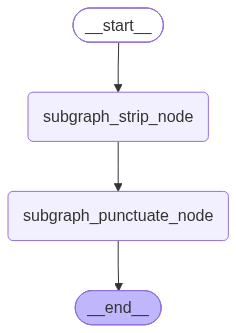

In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# 构建子图
class SubgraphState(TypedDict):
    raw_text: str # 未清洗文本
    stripped_text: str # 去除收尾空格的文本
    punctuated_text: str # 句尾添加句号的文本

def subgraph_strip_node(state: SubgraphState) -> SubgraphState:
    raw_text = state["raw_text"]
    stripped_text = raw_text.strip()

    return {
        "stripped_text": stripped_text
    }

def subgraph_punctuate_node(state: SubgraphState) -> SubgraphState:
    stripped_text = state["stripped_text"]
    punctuated_text = stripped_text + "。"

    return {
        "punctuated_text": punctuated_text
    }

builder = StateGraph(state_schema=SubgraphState)
builder.add_node("subgraph_strip_node", subgraph_strip_node)
builder.add_node("subgraph_punctuate_node", subgraph_punctuate_node)

builder.add_edge(START, "subgraph_strip_node")
builder.add_edge("subgraph_strip_node", "subgraph_punctuate_node")
builder.add_edge("subgraph_punctuate_node", END)
subgraph = builder.compile()

from IPython.display import display
display(subgraph)

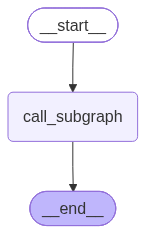

<class 'langgraph.graph.state.CompiledStateGraph'>


In [11]:
from rich import print as rprint
# 构建父图
class ParentState(TypedDict):
    input_text: str # 输入的未清洗的文本
    cleaned_text: str # 清洗后的文本

def call_subgraph(state: ParentState) -> ParentState:
    input_text = state["input_text"]

    res = subgraph.invoke({"raw_text": input_text})
    rprint(res)
    cleaned_text = res["punctuated_text"]
    return {
        "cleaned_text": cleaned_text
    }

builder = StateGraph(state_schema=ParentState)
builder.add_node("call_subgraph", call_subgraph)

builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

parent_graph = builder.compile()

display(parent_graph)
print(type(parent_graph))

In [4]:
input_text = "   LangGraph 真有意思        "
res = parent_graph.invoke({"input_text": input_text})
rprint(res)

{
    'raw_text': '   LangGraph 真有意思        ',
    'stripped_text': 'LangGraph 真有意思',
    'punctuated_text': 'LangGraph 真有意思。'
}

{'input_text': '   LangGraph 真有意思        ', 'cleaned_text': 'LangGraph 真有意思。'}

当节点返回一个字典时，LangGraph 会只保留那些在 State schema 里定义过的字段，没定义的字段被直接过滤掉，既不写入状态，也不报错。

调用 **`get_graph()`** 时传递的 **`xray=True`** 表示自动解析并递归获取子图的拓扑结构：

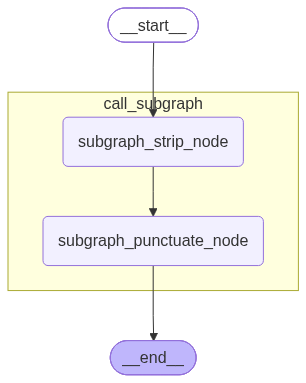

In [8]:
from IPython.display import Image

display(
    Image(parent_graph.get_graph(xray=True).draw_mermaid_png())
)

```python
get_graph(
  self,
  config: RunnableConfig | None = None,
  *,
  xray: int | bool = False,
  headers: dict[str, str] | None = None,
  params: QueryParamTypes | None = None
) -> DrawableGraph
```

当 **`xray=数字`** 时，LangGraph 会自动解析并递归获取响应子图的拓扑结构，**`xray`** 也可以传递一个整数，表示递归深度

文档说 `调用子图时最好不要链式调用`，这个问题在最新版本里已经没有出现。

In [10]:
list(parent_graph.get_subgraphs())

[('call_subgraph', <langgraph.graph.state.CompiledStateGraph at 0x1151e6d50>)]

这里返回了元组

| 值 | 含义 |
|---|---|
| `"call_subgraph"` | 子图的命名空间。这个例子中，就是父图里调用该子图的节点名，来自 `builder.add_node("call_subgraph", call_subgraph)` |
| `CompiledStateGraph` 对象 | 通过 `builder.compile()` 创建的子图本身，可以调用它的 `invoke()`、`get_graph()` 等方法 |

这里返回的是子图对象，不是子图执行后的结果或状态快照。0x19bd9e84ec0 是对象显示信息中的内存地址标识，不是子图 ID，不需要记住。

### 12.1.2 子图直接作为父图的节点


In [12]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# 定义全局共享状态
class OverAllState(TypedDict):
    raw_text: str # 未清洗文本
    cleaned_text: str # 清洗后的文本

# 构建子图
def subgraph_strip_node(state: OverAllState) -> OverAllState:
    raw_text = state["raw_text"]
    stripped_text = raw_text.strip()

    return {
        "cleaned_text": stripped_text
    }

def subgraph_punctuate_node(state: OverAllState) -> OverAllState:
    cleaned_text = state["cleaned_text"]
    punctuated_text = cleaned_text + "。"

    return {
        "cleaned_text": punctuated_text
    }

# 构建子图
builder = StateGraph(state_schema=OverAllState)
builder.add_node("subgraph_strip_node", subgraph_strip_node)
builder.add_node("subgraph_punctuate_node", subgraph_punctuate_node)

builder.add_edge(START, "subgraph_strip_node")
builder.add_edge("subgraph_strip_node", "subgraph_punctuate_node")
builder.add_edge("subgraph_punctuate_node", END)

subgraph = builder.compile()

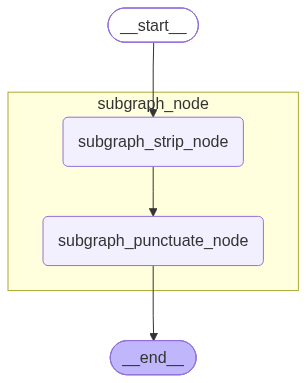

In [13]:
# 构建父图
builder = StateGraph(state_schema=OverAllState)
# 添加子图作为节点
builder.add_node("subgraph_node", subgraph)

builder.add_edge(START, "subgraph_node")
builder.add_edge("subgraph_node", END)

parent_graph = builder.compile()
display(
    Image(parent_graph.get_graph(xray=True).draw_mermaid_png())
)

In [14]:
raw_text = "   LangGraph 真有意思        "
res = parent_graph.invoke({"raw_text": raw_text})
rprint(res)

{'raw_text': '   LangGraph 真有意思        ', 'cleaned_text': 'LangGraph 真有意思。'}

## 12.2 子图持久化
### 12.2.1 查看子图检查点快照

示例选择 在节点中调用子图。

{'input_text': '   LangGraph 真有意思        ', 'cleaned_text': 'LangGraph 真有意思。'}

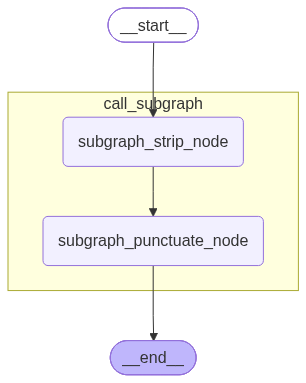

In [15]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

# 构建子图
class SubgraphState(TypedDict):
    raw_text: str # 未清洗文本
    stripped_text: str # 去除收尾空格的文本
    punctuated_text: str # 句尾添加句号的文本

def subgraph_strip_node(state: SubgraphState) -> SubgraphState:
    raw_text = state["raw_text"]
    stripped_text = raw_text.strip()

    return {
        "stripped_text": stripped_text
    }

def subgraph_punctuate_node(state: SubgraphState) -> SubgraphState:
    stripped_text = state["stripped_text"]
    punctuated_text = stripped_text + "。"

    return {
        "punctuated_text": punctuated_text
    }

builder = StateGraph(state_schema=SubgraphState)
builder.add_node("subgraph_strip_node", subgraph_strip_node)
builder.add_node("subgraph_punctuate_node", subgraph_punctuate_node)

builder.add_edge(START, "subgraph_strip_node")
builder.add_edge("subgraph_strip_node", "subgraph_punctuate_node")
builder.add_edge("subgraph_punctuate_node", END)

subgraph = builder.compile()

# 构建父图
class ParentState(TypedDict):
    input_text: str # 输入的未清洗的文本
    cleaned_text: str # 清洗后的文本

def call_subgraph(state: ParentState) -> ParentState:
    input_text = state["input_text"]

    res = subgraph.invoke({"raw_text": input_text})
    cleaned_text = res["punctuated_text"]
    return {
        "cleaned_text": cleaned_text
    }

builder = StateGraph(state_schema=ParentState)
builder.add_node("call_subgraph", call_subgraph)

builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

checkpointer=InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

input_text = "   LangGraph 真有意思        "
config={"configurable": {"thread_id": "observe_checkpoint_1"}}
res = parent_graph.invoke(
    {"input_text": input_text},
    config=config
)
rprint(res)

from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)

In [16]:
histories = list(parent_graph.get_state_history(config=config))
rprint(histories)

[
    StateSnapshot(
        values={'input_text': '   LangGraph 真有意思        ', 'cleaned_text': 'LangGraph 真有意思。'},
        next=(),
        config={
            'configurable': {
                'thread_id': 'observe_checkpoint_1',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cc9a4-7531-6c9e-8001-28d07bad3d37'
            }
        },
        metadata={'source': 'loop', 'step': 1, 'parents': {}},
        created_at='2026-10-20T15:24:01.885503+00:00',
        parent_config={
            'configurable': {
                'thread_id': 'observe_checkpoint_1',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cc9a4-7529-63aa-8000-dc6b676385e4'
            }
        },
        tasks=(),
        interrupts=()
    ),
    StateSnapshot(
        values={'input_text': '   LangGraph 真有意思        '},
        next=('call_subgraph',),
        config={
            'configurable': {
                'thread_id': 'observe_checkpoint_1',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cc9a4-7529-63aa-8000-dc6b676385e4'
            }
        },
        metadata={'source': 'loop', 'step': 0, 'parents': {}},
        created_at='2026-10-20T15:24:01.881997+00:00',
        parent_config={
            'configurable': {
                'thread_id': 'observe_checkpoint_1',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cc9a4-7528-6554-bfff-7eccda07879f'
            }
        },
        tasks=(
            PregelTask(
                id='ee5c622a-26a0-ee67-c855-cdea7de2100a',
                name='call_subgraph',
                path=('__pregel_pull', 'call_subgraph'),
                error=None,
                interrupts=(),
                state={
                    'configurable': {
                        'thread_id': 'observe_checkpoint_1',
                        'checkpoint_ns': 'call_subgraph:ee5c622a-26a0-ee67-c855-cdea7de2100a'
                    }
                },
                result={'cleaned_text': 'LangGraph 真有意思。'}
            ),
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={},
        next=('__start__',),
        config={
            'configurable': {
                'thread_id': 'observe_checkpoint_1',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cc9a4-7528-6554-bfff-7eccda07879f'
            }
        },
        metadata={'source': 'input', 'step': -1, 'parents': {}},
        created_at='2026-10-20T15:24:01.881629+00:00',
        parent_config=None,
        tasks=(
            PregelTask(
                id='8ab72add-8484-07a8-0381-85e02c8c6701',
                name='__start__',
                path=('__pregel_pull', '__start__'),
                error=None,
                interrupts=(),
                state=None,
                result={'input_text': '   LangGraph 真有意思        '}
            ),
        ),
        interrupts=()
    )
]

超步为 **`0`** 的快照下的 **`tasks`** 字段下只有一个任务实例，该任务实例在编号为 **`1`** 的超步执行，其中的 **`state`** 字段记录了子图检查点的 **`thread_id`** 和 **`checkpoint_ns`**，如下所示：

```json
state={
                    'configurable': {
                        'thread_id': 'observe_checkpoint_1',
                        'checkpoint_ns': 'call_subgraph:ee5c622a-26a0-ee67-c855-cdea7de2100a'
                    }
                },
```

- **`thread_id`**：整个线程的唯一 **`ID`**，和父图一致

- **`checkpoint_ns`**：子图命名空间，格式为`<子图所属父图节点名称>:<子图所属父图任务ID>`

我们在介绍 **`LangGraph`** 中提到，父图的 **`checkpoint_ns`** 通常为空字符串，在子图嵌套系统中该字段排上了用场：

- 父图的 **`checkpoint_ns`** 仍未空字符串
- 子图的 **`checkpoint_ns`** 遵循以上格式

当嵌套层级不止一层时，命名空间将会通过 **`|`** 拼接，具体来说，假设拓扑结构如下：

```python
父图
└── call_subgraph          # 调用子图 A
    └── call_inner_graph   # 子图 A 调用子图 B
```

那么命名空间为

```python
父图：
""

子图 A：
call_subgraph:<task_id_1>

子图 B：
call_subgraph:<task_id_1>|call_inner_graph:<task_id_2>
```

依次类推。

#### 12.2.1.1 在父图检查点快照中展开子图最新快照
我们可以在父图的 **`state`** 字段中展开子图快照，也就是将 **`state`** 字段的值替换为子图的最新检查点快照

In [17]:
parent_config = histories[-2].config
rprint(parent_config)

{
    'configurable': {
        'thread_id': 'observe_checkpoint_1',
        'checkpoint_ns': '',
        'checkpoint_id': '1f1cc9a4-7529-63aa-8000-dc6b676385e4'
    }
}

In [18]:
rprint(parent_graph.get_state(config=parent_config, subgraphs=True))

StateSnapshot(
    values={'input_text': '   LangGraph 真有意思        '},
    next=('call_subgraph',),
    config={
        'configurable': {
            'thread_id': 'observe_checkpoint_1',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1cc9a4-7529-63aa-8000-dc6b676385e4'
        }
    },
    metadata={'source': 'loop', 'step': 0, 'parents': {}},
    created_at='2026-10-20T15:24:01.881997+00:00',
    parent_config={
        'configurable': {
            'thread_id': 'observe_checkpoint_1',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1cc9a4-7528-6554-bfff-7eccda07879f'
        }
    },
    tasks=(
        PregelTask(
            id='ee5c622a-26a0-ee67-c855-cdea7de2100a',
            name='call_subgraph',
            path=('__pregel_pull', 'call_subgraph'),
            error=None,
            interrupts=(),
            state=StateSnapshot(
                values={
                    'raw_text': '   LangGraph 真有意思        ',
                    'stripped_text': 'LangGraph 真有意思',
                    'punctuated_text': 'LangGraph 真有意思。'
                },
                next=(),
                config={
                    'configurable': {
                        'thread_id': 'observe_checkpoint_1',
                        'checkpoint_ns': 'call_subgraph:ee5c622a-26a0-ee67-c855-cdea7de2100a',
                        'checkpoint_id': '1f1cc9a4-7530-672c-8002-a571417b9810',
                        'checkpoint_map': {
                            '': '1f1cc9a4-7529-63aa-8000-dc6b676385e4',
                            'call_subgraph:ee5c622a-26a0-ee67-c855-cdea7de2100a': 
'1f1cc9a4-7530-672c-8002-a571417b9810'
                        }
                    }
                },
                metadata={'source': 'loop', 'step': 2, 'parents': {'': '1f1cc9a4-7529-63aa-8000-dc6b676385e4'}},
                created_at='2026-10-20T15:24:01.884954+00:00',
                parent_config={
                    'configurable': {
                        'thread_id': 'observe_checkpoint_1',
                        'checkpoint_ns': 'call_subgraph:ee5c622a-26a0-ee67-c855-cdea7de2100a',
                        'checkpoint_id': '1f1cc9a4-752e-6896-8001-3c14467cb58a',
                        'checkpoint_map': {
                            '': '1f1cc9a4-7529-63aa-8000-dc6b676385e4',
                            'call_subgraph:ee5c622a-26a0-ee67-c855-cdea7de2100a': 
'1f1cc9a4-752e-6896-8001-3c14467cb58a'
                        }
                    }
                },
                tasks=(),
                interrupts=()
            ),
            result={'cleaned_text': 'LangGraph 真有意思。'}
        ),
    ),
    interrupts=()
)

#### 12.2.1.2 获取子图配置，查看完整子图检查点列表

某些场景下，我们希望查看完整的子图检查点快照列表，此时只需要将包含 **`thread_id`** 和子图命名空间 **`checkpoint_ns`** 的配置信息传递给 **`get_state_history()`** 即可实现。

In [22]:
child_config = parent_graph.get_state(config=parent_config, subgraphs=True).tasks[0].state.config
print(type(child_config))
rprint(child_config)

<class 'dict'>


{
    'configurable': {
        'thread_id': 'observe_checkpoint_1',
        'checkpoint_ns': 'call_subgraph:ee5c622a-26a0-ee67-c855-cdea7de2100a',
        'checkpoint_id': '1f1cc9a4-7530-672c-8002-a571417b9810',
        'checkpoint_map': {
            '': '1f1cc9a4-7529-63aa-8000-dc6b676385e4',
            'call_subgraph:ee5c622a-26a0-ee67-c855-cdea7de2100a': '1f1cc9a4-7530-672c-8002-a571417b9810'
        }
    }
}

In [23]:
rprint(list(parent_graph.get_state_history(config=child_config)))

[
    StateSnapshot(
        values={
            'raw_text': '   LangGraph 真有意思        ',
            'stripped_text': 'LangGraph 真有意思',
            'punctuated_text': 'LangGraph 真有意思。'
        },
        next=(),
        config={
            'configurable': {
                'thread_id': 'observe_checkpoint_1',
                'checkpoint_ns': 'call_subgraph:ee5c622a-26a0-ee67-c855-cdea7de2100a',
                'checkpoint_id': '1f1cc9a4-7530-672c-8002-a571417b9810',
                'checkpoint_map': {
                    '': '1f1cc9a4-7529-63aa-8000-dc6b676385e4',
                    'call_subgraph:ee5c622a-26a0-ee67-c855-cdea7de2100a': '1f1cc9a4-7530-672c-8002-a571417b9810'
                }
            }
        },
        metadata={'source': 'loop', 'step': 2, 'parents': {'': '1f1cc9a4-7529-63aa-8000-dc6b676385e4'}},
        created_at='2026-10-20T15:24:01.884954+00:00',
        parent_config={
            'configurable': {
                'thread_id': 'observe_checkpoint_1',
                'checkpoint_ns': 'call_subgraph:ee5c622a-26a0-ee67-c855-cdea7de2100a',
                'checkpoint_id': '1f1cc9a4-752e-6896-8001-3c14467cb58a',
                'checkpoint_map': {
                    '': '1f1cc9a4-7529-63aa-8000-dc6b676385e4',
                    'call_subgraph:ee5c622a-26a0-ee67-c855-cdea7de2100a': '1f1cc9a4-752e-6896-8001-3c14467cb58a'
                }
            }
        },
        tasks=(),
        interrupts=()
    )
]

- 上述快照的命名空间都不是空字符串，且保持一致，全部属于同一个子图

- **`metadata['parents']`** 记录了父检查点的信息，格式为

  **`<父检查点命名空间>:<父检查点ID>`**

- **`config['configurable']['checkpoint_map']`** 记录了父图和当前子图检查点命名空间和 **`ID`** 的映射关系，包含两个条目，格式如下

  ```python
  <父图检查点命名空间>:<父图检查点ID>,
  <当前子图检查点命名空间>:<当前子图检查点ID>
  ```

### 12.2.2. 持久化策略
本节讨论的持久化策略以**父图启用检查点存储器**为前提。子图支持三种策略：

| 策略                         | 编译参数                   | 检查点保存 | 中断恢复 | 多轮记忆                             |
| :--------------------------- | :------------------------- | :--------- | :------- | :----------------------------------- |
| **`Per-invocation`**（默认） | `checkpointer=None` 或省略 | ✓          | ✓        | ✗（同 thread_id 再次调用不加载历史） |
| **`Per-thread`**             | `checkpointer=True`        | ✓          | ✓        | ✓（同 thread_id 调用加载历史）       |
| **`Stateless`**              | `checkpointer=False`       | ✗          | ✗        | ✗                                    |


> **三种策略的唯一区别在于子图编译时的 `checkpointer` 参数**，其余代码完全相同。下面按场景组织，每个场景展示一份完整代码，策略切换只需修改一行。

#### 12.2.2.1 场景一：中断（interrupt）
子图节点中使用 `interrupt()` 中断执行，等待用户输入后恢复。

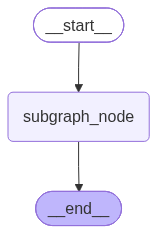

In [24]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver

from loguru import logger

# 定义全局共享状态
class OverAllState(TypedDict):
    raw_text: str # 未清洗文本
    cleaned_text: str # 清洗后的文本

# 构建子图
def subgraph_strip_node(state: OverAllState) -> OverAllState:
    logger.info("子图 subgraph_strip_node 节点执行了")
    raw_text = state["raw_text"]
    stripped_text = raw_text.strip()

    return {
        "cleaned_text": stripped_text
    }


def subgraph_punctuate_node(state: OverAllState) -> OverAllState:
    logger.info("子图 subgraph_punctuate_node 节点执行了")
    cleaned_text = state["cleaned_text"]
    punctuation = interrupt("您希望在句尾添加的标点符号是？[。/，/！/？/；]")
    punctuation1 = interrupt("您希望在句尾添加的标点符号是？[。/，/！/？/；]")
    punctuated_text = cleaned_text + punctuation + punctuation1

    return {
        "cleaned_text": punctuated_text
    }

# 构建子图
builder = StateGraph(state_schema=OverAllState)
builder.add_node("subgraph_strip_node", subgraph_strip_node)
builder.add_node("subgraph_punctuate_node", subgraph_punctuate_node)

builder.add_edge(START, "subgraph_strip_node")
builder.add_edge("subgraph_strip_node", "subgraph_punctuate_node")
builder.add_edge("subgraph_punctuate_node", END)

# ==================================================
# 【策略切换点】只需修改这一行
# subgraph = builder.compile()  # Per-invocation（默认）
# subgraph = builder.compile(checkpointer=True)   # Per-thread
subgraph = builder.compile(checkpointer=False)  # Stateless（中断不可用）
# ==================================================

# 这里使用了将子图作为节点的父图
# 构建父图
builder = StateGraph(state_schema=OverAllState)
builder.add_node("subgraph_node", subgraph)

builder.add_edge(START, "subgraph_node")
builder.add_edge("subgraph_node", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)

In [25]:
raw_text = "   LangGraph 真有意思        "
config = {"configurable": {"thread_id": "123"}}
# 首次调用
interrupted_res = parent_graph.invoke(
    {"raw_text": raw_text},
    config=config
)
rprint(interrupted_res)

2026-10-20 09:42:57.430 | INFO     | __main__:subgraph_strip_node:15 - 子图 subgraph_strip_node 节点执行了
2026-10-20 09:42:57.431 | INFO     | __main__:subgraph_punctuate_node:25 - 子图 subgraph_punctuate_node 节点执行了


{
    'raw_text': '   LangGraph 真有意思        ',
    '__interrupt__': [
        Interrupt(
            value='您希望在句尾添加的标点符号是？[。/，/！/？/；]',
            id='25d7cf34512b99b23a0b423cafdd4003',
            response_schema=None
        )
    ]
}

In [27]:
# 恢复调用
temp_res = parent_graph.invoke(
    Command(resume="!"),
    config=config
)
rprint(temp_res)

res = parent_graph.invoke(
    Command(resume="~"),
    config=config
)
rprint(res)

2026-10-20 09:44:16.606 | INFO     | __main__:subgraph_strip_node:15 - 子图 subgraph_strip_node 节点执行了
2026-10-20 09:44:16.607 | INFO     | __main__:subgraph_punctuate_node:25 - 子图 subgraph_punctuate_node 节点执行了


{
    'raw_text': '   LangGraph 真有意思        ',
    '__interrupt__': [
        Interrupt(
            value='您希望在句尾添加的标点符号是？[。/，/！/？/；]',
            id='5070deeb0d85acee08ca18cffd292730',
            response_schema=None
        )
    ]
}

2026-10-20 09:44:16.615 | INFO     | __main__:subgraph_strip_node:15 - 子图 subgraph_strip_node 节点执行了
2026-10-20 09:44:16.616 | INFO     | __main__:subgraph_punctuate_node:25 - 子图 subgraph_punctuate_node 节点执行了


{
    'raw_text': '   LangGraph 真有意思        ',
    '__interrupt__': [
        Interrupt(
            value='您希望在句尾添加的标点符号是？[。/，/！/？/；]',
            id='b1a2267ee5a96db99cc67e6000d3be05',
            response_schema=None
        )
    ]
}

使用 `checkpointer=True`

In [31]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver

from loguru import logger

# 定义全局共享状态
class OverAllState(TypedDict):
    raw_text: str # 未清洗文本
    cleaned_text: str # 清洗后的文本

# 构建子图
def subgraph_strip_node(state: OverAllState) -> OverAllState:
    logger.info("子图 subgraph_strip_node 节点执行了")
    raw_text = state["raw_text"]
    stripped_text = raw_text.strip()

    return {
        "cleaned_text": stripped_text
    }


def subgraph_punctuate_node(state: OverAllState) -> OverAllState:
    logger.info("子图 subgraph_punctuate_node 节点执行了")
    cleaned_text = state["cleaned_text"]
    punctuation = interrupt("您希望在句尾添加的标点符号是？[。/，/！/？/；]")
    punctuation1 = interrupt("您希望在句尾添加的标点符号是？[。/，/！/？/；]")
    punctuated_text = cleaned_text + punctuation + punctuation1

    return {
        "cleaned_text": punctuated_text
    }

# 构建子图
builder = StateGraph(state_schema=OverAllState)
builder.add_node("subgraph_strip_node", subgraph_strip_node)
builder.add_node("subgraph_punctuate_node", subgraph_punctuate_node)

builder.add_edge(START, "subgraph_strip_node")
builder.add_edge("subgraph_strip_node", "subgraph_punctuate_node")
builder.add_edge("subgraph_punctuate_node", END)

# ==================================================
# 【策略切换点】只需修改这一行
# subgraph = builder.compile()  # Per-invocation（默认）
# subgraph = builder.compile(checkpointer=True)   # Per-thread
subgraph = builder.compile(checkpointer=True)  # Per-thread：支持中断和跨调用记忆
# ==================================================

# 这里使用了将子图作为节点的父图
# 构建父图
builder = StateGraph(state_schema=OverAllState)
builder.add_node("subgraph_node", subgraph)

builder.add_edge(START, "subgraph_node")
builder.add_edge("subgraph_node", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)
raw_text = "   LangGraph 真有意思        "
config = {"configurable": {"thread_id": "123"}}
# 首次调用
interrupted_res = parent_graph.invoke(
    {"raw_text": raw_text},
    config=config
)
rprint(interrupted_res)
print("========================"*30)
# 恢复调用
temp_res = parent_graph.invoke(
    Command(resume="!"),
    config=config
)
rprint(temp_res)

res = parent_graph.invoke(
    Command(resume="~"),
    config=config
)
rprint(res)

2026-10-20 09:46:49.604 | INFO     | __main__:subgraph_strip_node:15 - 子图 subgraph_strip_node 节点执行了
2026-10-20 09:46:49.605 | INFO     | __main__:subgraph_punctuate_node:25 - 子图 subgraph_punctuate_node 节点执行了


{
    'raw_text': '   LangGraph 真有意思        ',
    '__interrupt__': [
        Interrupt(
            value='您希望在句尾添加的标点符号是？[。/，/！/？/；]',
            id='efbbd9071f81ebb2132d9a6277211030',
            response_schema=None
        )
    ]
}

2026-10-20 09:46:49.611 | INFO     | __main__:subgraph_punctuate_node:25 - 子图 subgraph_punctuate_node 节点执行了


{
    'raw_text': '   LangGraph 真有意思        ',
    '__interrupt__': [
        Interrupt(
            value='您希望在句尾添加的标点符号是？[。/，/！/？/；]',
            id='efbbd9071f81ebb2132d9a6277211030',
            response_schema=None
        )
    ]
}

2026-10-20 09:46:49.617 | INFO     | __main__:subgraph_punctuate_node:25 - 子图 subgraph_punctuate_node 节点执行了


{'raw_text': '   LangGraph 真有意思        ', 'cleaned_text': 'LangGraph 真有意思!~'}

情况3: 使用默认参数

In [34]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver

from loguru import logger

# 定义全局共享状态
class OverAllState(TypedDict):
    raw_text: str # 未清洗文本
    cleaned_text: str # 清洗后的文本

# 构建子图
def subgraph_strip_node(state: OverAllState) -> OverAllState:
    logger.info("子图 subgraph_strip_node 节点执行了")
    raw_text = state["raw_text"]
    stripped_text = raw_text.strip()

    return {
        "cleaned_text": stripped_text
    }


def subgraph_punctuate_node(state: OverAllState) -> OverAllState:
    logger.info("子图 subgraph_punctuate_node 节点执行了")
    cleaned_text = state["cleaned_text"]
    punctuation = interrupt("您希望在句尾添加的标点符号是？[。/，/！/？/；]")
    punctuation1 = interrupt("您希望在句尾添加的标点符号是？[。/，/！/？/；]")
    punctuated_text = cleaned_text + punctuation + punctuation1

    return {
        "cleaned_text": punctuated_text
    }

# 构建子图
builder = StateGraph(state_schema=OverAllState)
builder.add_node("subgraph_strip_node", subgraph_strip_node)
builder.add_node("subgraph_punctuate_node", subgraph_punctuate_node)

builder.add_edge(START, "subgraph_strip_node")
builder.add_edge("subgraph_strip_node", "subgraph_punctuate_node")
builder.add_edge("subgraph_punctuate_node", END)

# ==================================================
# 【策略切换点】只需修改这一行
# subgraph = builder.compile()  # Per-invocation（默认）
# subgraph = builder.compile(checkpointer=True)   # Per-thread
subgraph = builder.compile()  # Per-invocation：支持本次调用内的中断恢复
# ==================================================

# 这里使用了将子图作为节点的父图
# 构建父图
builder = StateGraph(state_schema=OverAllState)
builder.add_node("subgraph_node", subgraph)

builder.add_edge(START, "subgraph_node")
builder.add_edge("subgraph_node", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)
#parent_graph = builder.compile()
raw_text = "   LangGraph 真有意思        "
config = {"configurable": {"thread_id": "123"}}
# 首次调用
interrupted_res = parent_graph.invoke(
    {"raw_text": raw_text},
    config=config
)
rprint(interrupted_res)
print("========================"*30)
# 恢复调用
temp_res = parent_graph.invoke(
    Command(resume="!"),
    config=config
)
rprint(temp_res)

res = parent_graph.invoke(
    Command(resume="~"),
    config=config
)
rprint(res)

2026-10-20 09:50:34.317 | INFO     | __main__:subgraph_strip_node:15 - 子图 subgraph_strip_node 节点执行了
2026-10-20 09:50:34.318 | INFO     | __main__:subgraph_punctuate_node:25 - 子图 subgraph_punctuate_node 节点执行了


{
    'raw_text': '   LangGraph 真有意思        ',
    '__interrupt__': [
        Interrupt(
            value='您希望在句尾添加的标点符号是？[。/，/！/？/；]',
            id='2a3ca8fc3811993a6a051cc62860b897',
            response_schema=None
        )
    ]
}

2026-10-20 09:50:34.323 | INFO     | __main__:subgraph_punctuate_node:25 - 子图 subgraph_punctuate_node 节点执行了


{
    'raw_text': '   LangGraph 真有意思        ',
    '__interrupt__': [
        Interrupt(
            value='您希望在句尾添加的标点符号是？[。/，/！/？/；]',
            id='2a3ca8fc3811993a6a051cc62860b897',
            response_schema=None
        )
    ]
}

2026-10-20 09:50:34.330 | INFO     | __main__:subgraph_punctuate_node:25 - 子图 subgraph_punctuate_node 节点执行了


{'raw_text': '   LangGraph 真有意思        ', 'cleaned_text': 'LangGraph 真有意思!~'}

#### 12.2.2.2 场景二：多轮对话

父图多次调用子图进行 LLM 对话，验证子图是否保留历史消息。

In [40]:
import os
from typing import TypedDict
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from langchain.messages import HumanMessage, SystemMessage, AIMessage
import sys
from loguru import logger
# 删除 Loguru 默认的 stderr sink
logger.remove()
# 重新添加支持颜色的 sink
logger.add(sys.stdout, colorize=True)

from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

In [41]:
# 构建子图
def llm_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    logger.info("=" * 30)
    logger.info("调用子图的 llm_node 节点，当前的 messages: ")
    for index, message in enumerate(messages, start=1):
        logger.opt(colors=True).info(
            "\n<cyan><bold>[消息 {}]</bold></cyan>\n"
            "<yellow>类型：</yellow><magenta>{}</magenta>\n"
            "<yellow>内容：</yellow><green>{}</green>",
            index,
            message.type,
            message.content
        )
    logger.info("=" * 30)

    response = model.invoke(input=messages)
    ai_msg = AIMessage(content=response.content)

    return {
        "messages": [ai_msg]
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", END)

# ==================================================
# 【策略切换点】只需修改这一行
subgraph = builder.compile()  # Per-invocation（默认）：无记忆
# subgraph = builder.compile(checkpointer=True)   # Per-thread：有记忆
# ==================================================

# 构建父图
class OverAllState(TypedDict):
    user_input: str # 用户提问
    assistant_response: str # 助手回答

def call_subgraph(state: OverAllState) -> OverAllState:
    user_input = state["user_input"]
    # 生成消息列表
    messages = [
        SystemMessage("尽可能用简短的语言回答"),
        HumanMessage(user_input)
    ]
    subgraph_response = subgraph.invoke(
        {"messages": messages}
    )

    assistant_response = subgraph_response["messages"][-1].content

    return {
        "assistant_response": assistant_response
    }

In [42]:
builder = StateGraph(state_schema=OverAllState)
builder.add_node("call_subgraph", call_subgraph)
builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "multi-turn-demo"}}

first_invoke = parent_graph.invoke(
    {"user_input": "我是老王，从现在开始，你是小王"},
    config = config
)
rprint(first_invoke)

2026-10-20 10:14:43.221 | INFO     | __main__:llm_node:4 - ==============================
2026-10-20 10:14:43.221 | INFO     | __main__:llm_node:5 - 调用子图的 llm_node 节点，当前的 messages: 
2026-10-20 10:14:43.221 | INFO     | __main__:llm_node:7 - 
[消息 1]
类型：system
内容：尽可能用简短的语言回答
2026-10-20 10:14:43.222 | INFO     | __main__:llm_node:7 - 
[消息 2]
类型：human
内容：我是老王，从现在开始，你是小王
2026-10-20 10:14:43.222 | INFO     | __main__:llm_node:15 - ==============================


{'user_input': '我是老王，从现在开始，你是小王', 'assistant_response': ' 好的，老王。我是小王。'}

In [43]:
second_invoke = parent_graph.invoke(
    {"user_input": "我是谁？你是谁？"},
    config = config
)
print("=" * 30, "-> 第二次调用 <-", "=" * 30)
rprint(second_invoke)

2026-10-20 10:18:16.183 | INFO     | __main__:llm_node:4 - ==============================
2026-10-20 10:18:16.183 | INFO     | __main__:llm_node:5 - 调用子图的 llm_node 节点，当前的 messages: 
2026-10-20 10:18:16.184 | INFO     | __main__:llm_node:7 - 
[消息 1]
类型：system
内容：尽可能用简短的语言回答
2026-10-20 10:18:16.184 | INFO     | __main__:llm_node:7 - 
[消息 2]
类型：human
内容：我是谁？你是谁？
2026-10-20 10:18:16.184 | INFO     | __main__:llm_node:15 - ==============================
============================== -> 第二次调用 <- ==============================


{
    'user_input': '我是谁？你是谁？',
    'assistant_response': '你是正在和我对话的用户。\n\n我是 Codex，一个基于 GPT-5 
的编程助手，负责协助你阅读、修改和验证代码。'
}

2. 第二种情况,只有为 True时加载之前的记忆

In [45]:
# 构建子图
def llm_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    logger.info("=" * 30)
    logger.info("调用子图的 llm_node 节点，当前的 messages: ")
    for index, message in enumerate(messages, start=1):
        logger.opt(colors=True).info(
            "\n<cyan><bold>[消息 {}]</bold></cyan>\n"
            "<yellow>类型：</yellow><magenta>{}</magenta>\n"
            "<yellow>内容：</yellow><green>{}</green>",
            index,
            message.type,
            message.content
        )
    logger.info("=" * 30)

    response = model.invoke(input=messages)
    ai_msg = AIMessage(content=response.content)

    return {
        "messages": [ai_msg]
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", END)

# ==================================================
# 【策略切换点】只需修改这一行
subgraph = builder.compile(checkpointer=True)  # Per-invocation（默认）：无记忆
# subgraph = builder.compile(checkpointer=True)   # Per-thread：有记忆
# ==================================================

# 构建父图
class OverAllState(TypedDict):
    user_input: str # 用户提问
    assistant_response: str # 助手回答

def call_subgraph(state: OverAllState) -> OverAllState:
    user_input = state["user_input"]
    # 生成消息列表
    messages = [
        SystemMessage("尽可能用简短的语言回答"),
        HumanMessage(user_input)
    ]
    subgraph_response = subgraph.invoke(
        {"messages": messages}
    )

    assistant_response = subgraph_response["messages"][-1].content

    return {
        "assistant_response": assistant_response
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("call_subgraph", call_subgraph)
builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "multi-turn-demo"}}

first_invoke = parent_graph.invoke(
    {"user_input": "我是老王，从现在开始，你是小王"},
    config = config
)
rprint(first_invoke)

print("========="*10)
second_invoke = parent_graph.invoke(
    {"user_input": "我是谁？你是谁？"},
    config = config
)
print("=" * 30, "-> 第二次调用 <-", "=" * 30)
rprint(second_invoke)

2026-10-20 10:23:00.005 | INFO     | __main__:llm_node:4 - ==============================
2026-10-20 10:23:00.005 | INFO     | __main__:llm_node:5 - 调用子图的 llm_node 节点，当前的 messages: 
2026-10-20 10:23:00.006 | INFO     | __main__:llm_node:7 - 
[消息 1]
类型：system
内容：尽可能用简短的语言回答
2026-10-20 10:23:00.006 | INFO     | __main__:llm_node:7 - 
[消息 2]
类型：human
内容：我是老王，从现在开始，你是小王
2026-10-20 10:23:00.006 | INFO     | __main__:llm_node:15 - ==============================


{'user_input': '我是老王，从现在开始，你是小王', 'assistant_response': ' 好的，老王。我是小王。'}

2026-10-20 10:23:09.182 | INFO     | __main__:llm_node:4 - ==============================
2026-10-20 10:23:09.183 | INFO     | __main__:llm_node:5 - 调用子图的 llm_node 节点，当前的 messages: 
2026-10-20 10:23:09.183 | INFO     | __main__:llm_node:7 - 
[消息 1]
类型：system
内容：尽可能用简短的语言回答
2026-10-20 10:23:09.183 | INFO     | __main__:llm_node:7 - 
[消息 2]
类型：human
内容：我是老王，从现在开始，你是小王
2026-10-20 10:23:09.184 | INFO     | __main__:llm_node:7 - 
[消息 3]
类型：ai
内容： 好的，老王。我是小王。
2026-10-20 10:23:09.184 | INFO     | __main__:llm_node:7 - 
[消息 4]
类型：system
内容：尽可能用简短的语言回答
2026-10-20 10:23:09.185 | INFO     | __main__:llm_node:7 - 
[消息 5]
类型：human
内容：我是谁？你是谁？
2026-10-20 10:23:09.185 | INFO     | __main__:llm_node:15 - ==============================
============================== -> 第二次调用 <- ==============================


{'user_input': '我是谁？你是谁？', 'assistant_response': ' 你是老王，我是小王。'}

历史消息被保留，上下文连续。**Per-thread 模式适用于子图多轮对话场景。**

> **策略差异**

| 策略                   | 编译参数                                        | 多轮记忆           |
| :--------------------- | :---------------------------------------------- | :----------------- |
| Per-invocation（默认） | `subgraph = builder.compile()`                  | ❌ 每次调用状态重置 |
| Per-thread             | `subgraph = builder.compile(checkpointer=True)` | ✅ 跨调用状态连续   |

#### 12.2.2.3 场景三：多次调用同一子图
父图的一个节点内循环多次调用同一子图。

In [5]:
import os
from typing import TypedDict
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from langchain.messages import HumanMessage, SystemMessage, AIMessage
import sys
from loguru import logger
# 删除 Loguru 默认的 stderr sink
logger.remove()
# 重新添加支持颜色的 sink
logger.add(sys.stdout, colorize=True)

from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

# 构建子图
def llm_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    logger.info("=" * 30)
    logger.info("调用子图的 llm_node 节点，当前的 messages: ")
    for index, message in enumerate(messages, start=1):
        logger.opt(colors=True).info(
            "\n<cyan><bold>[消息 {}]</bold></cyan>\n"
            "<yellow>类型：</yellow><magenta>{}</magenta>\n"
            "<yellow>内容：</yellow><green>{}</green>",
            index,
            message.type,
            message.content
        )
    logger.info("=" * 30)
    # 返回的是AIMessage?
    response = model.invoke(input=messages)
    ai_msg = AIMessage(content=response.content)

    return {
        "messages": [ai_msg]
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", END)

# ==================================================
# 【策略切换点】只需修改这一行
subgraph = builder.compile()  # Per-invocation（默认）：每次调用状态隔离
# subgraph = builder.compile(checkpointer=True)   # Per-thread：历史相互干扰
# ==================================================

# 构建父图
class OverAllState(TypedDict):
    user_inputs: list[str] # 用户提问
    assistant_responses: str # 助手回答

def call_subgraph(state: OverAllState) -> OverAllState:
    # 获取用户输入
    user_inputs = state["user_inputs"]

    assistant_responses = []
    for user_input in user_inputs:
        subgraph_response = subgraph.invoke(
            {
                "messages": [
                    SystemMessage("用最简短的话回答用户的提问"),
                    HumanMessage(user_input)
                ]
            }
        )
        # 得到完整的消息回复列表
        assistant_response = subgraph_response["messages"][-1].content
        assistant_responses.append(assistant_response)

    return {
        "assistant_responses": assistant_responses
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("call_subgraph", call_subgraph)
builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

In [7]:
config = {"configurable": {"thread_id": "multi-call-same-demo"}}
from rich import print as rprint
first_response = parent_graph.invoke(
    {
        "user_inputs": [
            "5*5等于几",
            "10*10等于几"
        ]
    },
    config = config
)
rprint(first_response)

2026-10-20 19:29:08.068 | INFO     | __main__:llm_node:31 - ==============================
2026-10-20 19:29:08.068 | INFO     | __main__:llm_node:32 - 调用子图的 llm_node 节点，当前的 messages: 
2026-10-20 19:29:08.068 | INFO     | __main__:llm_node:34 - 
[消息 1]
类型：system
内容：用最简短的话回答用户的提问
2026-10-20 19:29:08.068 | INFO     | __main__:llm_node:34 - 
[消息 2]
类型：human
内容：5*5等于几
2026-10-20 19:29:08.069 | INFO     | __main__:llm_node:42 - ==============================
2026-10-20 19:29:29.452 | INFO     | __main__:llm_node:31 - ==============================
2026-10-20 19:29:29.453 | INFO     | __main__:llm_node:32 - 调用子图的 llm_node 节点，当前的 messages: 
2026-10-20 19:29:29.453 | INFO     | __main__:llm_node:34 - 
[消息 1]
类型：system
内容：用最简短的话回答用户的提问
2026-10-20 19:29:29.453 | INFO     | __main__:llm_node:34 - 
[消息 2]
类型：human
内容：10*10等于几
2026-10-20 19:29:29.453 | INFO     | __main__:llm_node:42 - ==============================


{'user_inputs': ['5*5等于几', '10*10等于几'], 'assistant_responses': ['25', '100']}

2026-10-20 19:30:25.663 | INFO     | __main__:llm_node:31 - ==============================
2026-10-20 19:30:25.664 | INFO     | __main__:llm_node:32 - 调用子图的 llm_node 节点，当前的 messages: 
2026-10-20 19:30:25.664 | INFO     | __main__:llm_node:34 - 
[消息 1]
类型：system
内容：用最简短的话回答用户的提问
2026-10-20 19:30:25.664 | INFO     | __main__:llm_node:34 - 
[消息 2]
类型：human
内容：再+1呢?
2026-10-20 19:30:25.665 | INFO     | __main__:llm_node:42 - ==============================
2026-10-20 19:30:29.841 | INFO     | __main__:llm_node:31 - ==============================
2026-10-20 19:30:29.842 | INFO     | __main__:llm_node:32 - 调用子图的 llm_node 节点，当前的 messages: 
2026-10-20 19:30:29.842 | INFO     | __main__:llm_node:34 - 
[消息 1]
类型：system
内容：用最简短的话回答用户的提问
2026-10-20 19:30:29.842 | INFO     | __main__:llm_node:34 - 
[消息 2]
类型：human
内容：再+10000呢?
2026-10-20 19:30:29.843 | INFO     | __main__:llm_node:42 - ==============================
============================== -> 第二次运行结果 <- ==============================


{
    'user_inputs': ['再+1呢?', '再+10000呢?'],
    'assistant_responses': ['你想给哪个数再加 1？', '在原来的基础上再加 10000。']
}

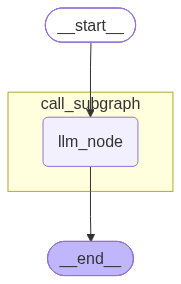

In [8]:
second_response = parent_graph.invoke(
    {
        "user_inputs": [
            "再+1呢?",
            "再+10000呢?"
        ]
    },
    config = config
)
print("=" * 30, "-> 第二次运行结果 <-", "=" * 30)
rprint(second_response)
from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)

2026-10-20 19:33:46.776 | INFO     | __main__:llm_node:31 - ==============================
2026-10-20 19:33:46.776 | INFO     | __main__:llm_node:32 - 调用子图的 llm_node 节点，当前的 messages: 
2026-10-20 19:33:46.777 | INFO     | __main__:llm_node:34 - 
[消息 1]
类型：system
内容：用最简短的话回答用户的提问
2026-10-20 19:33:46.777 | INFO     | __main__:llm_node:34 - 
[消息 2]
类型：human
内容：5*5等于几
2026-10-20 19:33:46.777 | INFO     | __main__:llm_node:42 - ==============================
2026-10-20 19:33:58.128 | INFO     | __main__:llm_node:31 - ==============================
2026-10-20 19:33:58.129 | INFO     | __main__:llm_node:32 - 调用子图的 llm_node 节点，当前的 messages: 
2026-10-20 19:33:58.129 | INFO     | __main__:llm_node:34 - 
[消息 1]
类型：system
内容：用最简短的话回答用户的提问
2026-10-20 19:33:58.130 | INFO     | __main__:llm_node:34 - 
[消息 2]
类型：human
内容：10*10等于几
2026-10-20 19:33:58.131 | INFO     | __main__:llm_node:42 - ==============================


{'user_inputs': ['5*5等于几', '10*10等于几'], 'assistant_responses': ['25', '100']}

2026-10-20 19:34:10.502 | INFO     | __main__:llm_node:31 - ==============================
2026-10-20 19:34:10.502 | INFO     | __main__:llm_node:32 - 调用子图的 llm_node 节点，当前的 messages: 
2026-10-20 19:34:10.503 | INFO     | __main__:llm_node:34 - 
[消息 1]
类型：system
内容：用最简短的话回答用户的提问
2026-10-20 19:34:10.503 | INFO     | __main__:llm_node:34 - 
[消息 2]
类型：human
内容：5*5等于几
2026-10-20 19:34:10.503 | INFO     | __main__:llm_node:34 - 
[消息 3]
类型：ai
内容：25
2026-10-20 19:34:10.504 | INFO     | __main__:llm_node:34 - 
[消息 4]
类型：system
内容：用最简短的话回答用户的提问
2026-10-20 19:34:10.505 | INFO     | __main__:llm_node:34 - 
[消息 5]
类型：human
内容：再+1呢?
2026-10-20 19:34:10.505 | INFO     | __main__:llm_node:42 - ==============================
2026-10-20 19:34:12.414 | INFO     | __main__:llm_node:31 - ==============================
2026-10-20 19:34:12.414 | INFO     | __main__:llm_node:32 - 调用子图的 llm_node 节点，当前的 messages: 
2026-10-20 19:34:12.414 | INFO     | __main__:llm_node:34 - 
[消息 1]
类型：system
内容：用最简短的话回答用户的提问
202

{'user_inputs': ['再+1呢?', '再+10000呢?'], 'assistant_responses': ['26', '10100']}

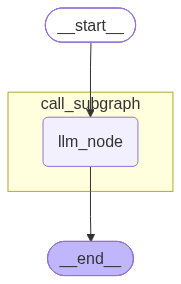

In [9]:
import os
from typing import TypedDict
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from langchain.messages import HumanMessage, SystemMessage, AIMessage
import sys
from loguru import logger
# 删除 Loguru 默认的 stderr sink
logger.remove()
# 重新添加支持颜色的 sink
logger.add(sys.stdout, colorize=True)

from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

# 构建子图
def llm_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    logger.info("=" * 30)
    logger.info("调用子图的 llm_node 节点，当前的 messages: ")
    for index, message in enumerate(messages, start=1):
        logger.opt(colors=True).info(
            "\n<cyan><bold>[消息 {}]</bold></cyan>\n"
            "<yellow>类型：</yellow><magenta>{}</magenta>\n"
            "<yellow>内容：</yellow><green>{}</green>",
            index,
            message.type,
            message.content
        )
    logger.info("=" * 30)
    # 返回的是AIMessage?
    response = model.invoke(input=messages)
    ai_msg = AIMessage(content=response.content)

    return {
        "messages": [ai_msg]
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", END)

# ==================================================
# 【策略切换点】只需修改这一行
#subgraph = builder.compile()  # Per-invocation（默认）：每次调用状态隔离
subgraph = builder.compile(checkpointer=True)   # Per-thread：历史相互干扰
# ==================================================

# 构建父图
class OverAllState(TypedDict):
    user_inputs: list[str] # 用户提问
    assistant_responses: str # 助手回答

def call_subgraph(state: OverAllState) -> OverAllState:
    # 获取用户输入
    user_inputs = state["user_inputs"]

    assistant_responses = []
    for user_input in user_inputs:
        subgraph_response = subgraph.invoke(
            {
                "messages": [
                    SystemMessage("用最简短的话回答用户的提问"),
                    HumanMessage(user_input)
                ]
            }
        )
        # 得到完整的消息回复列表
        assistant_response = subgraph_response["messages"][-1].content
        assistant_responses.append(assistant_response)

    return {
        "assistant_responses": assistant_responses
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("call_subgraph", call_subgraph)
builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "multi-call-same-demo"}}
from rich import print as rprint
first_response = parent_graph.invoke(
    {
        "user_inputs": [
            "5*5等于几",
            "10*10等于几"
        ]
    },
    config = config
)
rprint(first_response)

second_response = parent_graph.invoke(
    {
        "user_inputs": [
            "再+1呢?",
            "再+10000呢?"
        ]
    },
    config = config
)
print("=" * 30, "-> 第二次运行结果 <-", "=" * 30)
rprint(second_response)
from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)

每次调用子图时 `messages` 状态都是独立的。**Per-invocation 适用于父图中多次调用同一子图的场景，调用间互不干扰。**

**Per-thread 行为**（改为 `builder.compile(checkpointer=True)`）：同一节点内的多次子图调用，历史按调用位置独立——即第一次子图调用的历史是连续的，第二次子图调用的历史也是连续的，但两次之间独立。**如果调用顺序发生变化，检查点历史会相互干扰。**

> **策略差异**

| 策略                   | 编译参数                                        | 多次调用同一子图           |
| :--------------------- | :---------------------------------------------- | :------------------------- |
| Per-invocation（默认） | `subgraph = builder.compile()`                  | ✅ 每次调用完全隔离         |
| Per-thread             | `subgraph = builder.compile(checkpointer=True)` | ❌ 历史按位置关联，可能干扰 |

#### 12.2.2.4 场景四：多次调用不同子图
父图的一个节点内调用两个不同的子图。

In [12]:
import os
from typing import TypedDict
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from langchain.messages import HumanMessage, SystemMessage, AIMessage
import sys
from loguru import logger
# 删除 Loguru 默认的 stderr sink
logger.remove()
# 重新添加支持颜色的 sink
logger.add(sys.stdout, colorize=True)

from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

# ==================================================
# 【策略切换点】两个子图的编译参数
# ==================================================

# 构建水果子图
def fruit_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    logger.info("=" * 30)
    logger.info("调用水果子图的 fruit_node 节点，当前的 messages: ")
    for index, message in enumerate(messages, start=1):
        logger.opt(colors=True).info(
            "\n<cyan><bold>[消息 {}]</bold></cyan>\n"
            "<yellow>类型：</yellow><magenta>{}</magenta>\n"
            "<yellow>内容：</yellow><green>{}</green>",
            index,
            message.type,
            message.content
        )
    logger.info("=" * 30)
    response = model.invoke(input=messages)
    ai_msg = AIMessage(content=response.content)

    return {
        "messages": [ai_msg]
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("fruit_node", fruit_node)
builder.add_edge(START, "fruit_node")
builder.add_edge("fruit_node", END)

fruit_subgraph = builder.compile(checkpointer=True)

# 构建蔬菜子图
def vegetable_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    logger.info("=" * 30)
    logger.info("调用蔬菜子图的 vegetable_node 节点，当前的 messages: ")
    for index, message in enumerate(messages, start=1):
        logger.opt(colors=True).info(
            "\n<cyan><bold>[消息 {}]</bold></cyan>\n"
            "<yellow>类型：</yellow><magenta>{}</magenta>\n"
            "<yellow>内容：</yellow><green>{}</green>",
            index,
            message.type,
            message.content
        )
    logger.info("=" * 30)
    response = model.invoke(input=messages)
    ai_msg = AIMessage(content=response.content)

    return {
        "messages": [ai_msg]
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("vegetable_node", vegetable_node)
builder.add_edge(START, "vegetable_node")
builder.add_edge("vegetable_node", END)

vegetable_subgraph = builder.compile(checkpointer=True)

In [13]:
# 构建父图
class OverAllState(TypedDict):
    fruit: str # 水果
    vegetable: str # 蔬菜

    fruit_introduction: str # 水果介绍
    vegetable_introduction: str # 蔬菜介绍
# 函数内调用子图
def call_subgraph(state: OverAllState) -> OverAllState:
    fruit = state["fruit"]
    vegetable = state["vegetable"]

    fruit_messages = [
        SystemMessage("用最简短的话介绍用户输入的水果"),
        HumanMessage(fruit)
    ]

    vegetable_messages = [
        SystemMessage("用最简短的话介绍用户输入的蔬菜"),
        HumanMessage(vegetable)
    ]

    fruit_response = fruit_subgraph.invoke({"messages": fruit_messages})
    vegetable_response = vegetable_subgraph.invoke({"messages": vegetable_messages})

    fruit_introduction = fruit_response["messages"][-1].content
    vegetable_introduction = vegetable_response["messages"][-1].content

    return {
        "fruit_introduction": fruit_introduction,
        "vegetable_introduction": vegetable_introduction
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("call_subgraph", call_subgraph)
builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)
checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "multi-call-diff-demo"}}

first_response = parent_graph.invoke(
    {
        "fruit": "桑葚",
        "vegetable": "西兰苔"
    },
    config = config
)
print("=" * 30, "-> 第一次运行结果 <-", "=" * 30)
rprint(first_response)

2026-10-20 19:55:22.081 | INFO     | __main__:fruit_node:35 - ==============================
2026-10-20 19:55:22.081 | INFO     | __main__:fruit_node:36 - 调用水果子图的 fruit_node 节点，当前的 messages: 
2026-10-20 19:55:22.082 | INFO     | __main__:fruit_node:38 - 
[消息 1]
类型：system
内容：用最简短的话介绍用户输入的水果
2026-10-20 19:55:22.082 | INFO     | __main__:fruit_node:38 - 
[消息 2]
类型：human
内容：桑葚
2026-10-20 19:55:22.082 | INFO     | __main__:fruit_node:46 - ==============================
2026-10-20 19:55:25.616 | INFO     | __main__:vegetable_node:64 - ==============================
2026-10-20 19:55:25.617 | INFO     | __main__:vegetable_node:65 - 调用蔬菜子图的 vegetable_node 节点，当前的 messages: 
2026-10-20 19:55:25.617 | INFO     | __main__:vegetable_node:67 - 
[消息 1]
类型：system
内容：用最简短的话介绍用户输入的蔬菜
2026-10-20 19:55:25.617 | INFO     | __main__:vegetable_node:67 - 
[消息 2]
类型：human
内容：西兰苔
2026-10-20 19:55:25.618 | INFO     | __main__:vegetable_node:75 - ==============================
============================== -> 第一次

{
    'fruit': '桑葚',
    'vegetable': '西兰苔',
    'fruit_introduction': '桑葚：酸甜多汁的紫黑色小浆果。',
    'vegetable_introduction': '西兰苔：一种十字花科蔬菜，口感脆嫩，富含维生素C、膳食纤维和叶酸。'
}

2026-10-20 19:56:13.910 | INFO     | __main__:fruit_node:35 - ==============================
2026-10-20 19:56:13.911 | INFO     | __main__:fruit_node:36 - 调用水果子图的 fruit_node 节点，当前的 messages: 
2026-10-20 19:56:13.911 | INFO     | __main__:fruit_node:38 - 
[消息 1]
类型：system
内容：用最简短的话介绍用户输入的水果
2026-10-20 19:56:13.911 | INFO     | __main__:fruit_node:38 - 
[消息 2]
类型：human
内容：桑葚
2026-10-20 19:56:13.912 | INFO     | __main__:fruit_node:38 - 
[消息 3]
类型：ai
内容：桑葚：酸甜多汁的紫黑色小浆果。
2026-10-20 19:56:13.912 | INFO     | __main__:fruit_node:38 - 
[消息 4]
类型：system
内容：用最简短的话介绍用户输入的水果
2026-10-20 19:56:13.912 | INFO     | __main__:fruit_node:38 - 
[消息 5]
类型：human
内容：香蕉
2026-10-20 19:56:13.912 | INFO     | __main__:fruit_node:46 - ==============================
2026-10-20 19:56:31.528 | INFO     | __main__:vegetable_node:64 - ==============================
2026-10-20 19:56:31.528 | INFO     | __main__:vegetable_node:65 - 调用蔬菜子图的 vegetable_node 节点，当前的 messages: 
2026-10-20 19:56:31.529 | INFO     | __main__:ve

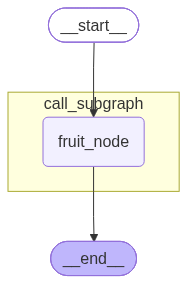

In [14]:
second_response = parent_graph.invoke(
    {
        "fruit": "香蕉",
        "vegetable": "西兰花"
    },
    config = config
)
print("=" * 30, "-> 第二次运行结果 <-", "=" * 30)
print(second_response)

from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)

本例在同一个节点中多次调用不同子图，通过专有状态保证了**水果一定发给 `fruit_subgraph`**、**蔬菜一定发给 `vegetable_subgraph`**，一定程度上可以确保不同子图的检查点历史不相互干扰。

但这种靠调用顺序区分的方式不够稳健——如果调用顺序变化，检查点历史也会错乱。官方推荐的做法见下一节。

#### 12.2.2.5 场景五：独立节点调用不同子图（推荐）
为每个子图准备独立的父图节点，这样它们的命名空间是各自的节点名，完全独立。

In [16]:
import os
from typing import Literal, Sequence, TypedDict
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from langchain.messages import HumanMessage, SystemMessage, AIMessage
import sys
from loguru import logger
# 删除 Loguru 默认的 stderr sink
logger.remove()
# 重新添加支持颜色的 sink
logger.add(sys.stdout, colorize=True)

from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

# 构建水果子图
def fruit_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    logger.info("=" * 30)
    logger.info("调用水果子图的 fruit_node 节点，当前的 messages: ")
    for index, message in enumerate(messages, start=1):
        logger.opt(colors=True).info(
            "\n<cyan><bold>[消息 {}]</bold></cyan>\n"
            "<yellow>类型：</yellow><magenta>{}</magenta>\n"
            "<yellow>内容：</yellow><green>{}</green>",
            index,
            message.type,
            message.content
        )
    logger.info("=" * 30)
    response = model.invoke(input=messages)
    ai_msg = AIMessage(content=response.content)

    return {
        "messages": [ai_msg]
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("fruit_node", fruit_node)
builder.add_edge(START, "fruit_node")
builder.add_edge("fruit_node", END)

fruit_subgraph = builder.compile(checkpointer=True)

# 构建蔬菜子图
def vegetable_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    logger.info("=" * 30)
    logger.info("调用蔬菜子图的 vegetable_node 节点，当前的 messages: ")
    for index, message in enumerate(messages, start=1):
        logger.opt(colors=True).info(
            "\n<cyan><bold>[消息 {}]</bold></cyan>\n"
            "<yellow>类型：</yellow><magenta>{}</magenta>\n"
            "<yellow>内容：</yellow><green>{}</green>",
            index,
            message.type,
            message.content
        )
    logger.info("=" * 30)
    response = model.invoke(input=messages)
    ai_msg = AIMessage(content=response.content)

    return {
        "messages": [ai_msg]
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("vegetable_node", vegetable_node)
builder.add_edge(START, "vegetable_node")
builder.add_edge("vegetable_node", END)

vegetable_subgraph = builder.compile(checkpointer=True)

# 构建父图
class OverAllState(TypedDict):
    fruit: str # 水果
    vegetable: str # 蔬菜

    fruit_introduction: str # 水果介绍
    vegetable_introduction: str # 蔬菜介绍

def call_fruit_subgraph(state: OverAllState) -> OverAllState:
    fruit = state["fruit"]

    fruit_messages = [
        SystemMessage("用最简短的话介绍用户输入的水果"),
        HumanMessage(fruit)
    ]

    fruit_response = fruit_subgraph.invoke({"messages": fruit_messages})
    fruit_introduction = fruit_response["messages"][-1].content

    return {
        "fruit_introduction": fruit_introduction
    }

def call_vegetable_subgraph(state: OverAllState) -> OverAllState:
    vegetable = state["vegetable"]

    vegetable_messages = [
        SystemMessage("用最简短的话介绍用户输入的蔬菜"),
        HumanMessage(vegetable)
    ]

    vegetable_response = vegetable_subgraph.invoke({"messages": vegetable_messages})
    vegetable_introduction = vegetable_response["messages"][-1].content

    return {
        "vegetable_introduction": vegetable_introduction
    }

def router(state: OverAllState) -> Sequence[Literal["call_fruit_subgraph", "call_vegetable_subgraph", END]]:
    next_nodes = []
    if state.get("fruit"):
        next_nodes.append("call_fruit_subgraph")
    if state.get("vegetable"):
        next_nodes.append("call_vegetable_subgraph")
    if not next_nodes:
        next_nodes.append(END)
    return next_nodes

builder = StateGraph(state_schema=OverAllState)
builder.add_node("call_fruit_subgraph", call_fruit_subgraph)
builder.add_node("call_vegetable_subgraph", call_vegetable_subgraph)

builder.add_conditional_edges(START, router, path_map=["call_fruit_subgraph", "call_vegetable_subgraph", END])
builder.add_edge("call_fruit_subgraph", END)
builder.add_edge("call_vegetable_subgraph", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "independent-nodes-demo"}}

first_response = parent_graph.invoke(
    {
        "fruit": "桑葚",
        "vegetable": "西兰苔"
    },
    config = config
)
print("=" * 30, "-> 第一次运行结果 <-", "=" * 30)
rprint(first_response)

2026-10-20 20:29:32.524 | INFO     | __main__:fruit_node:31 - ==============================
2026-10-20 20:29:32.525 | INFO     | __main__:vegetable_node:60 - ==============================
2026-10-20 20:29:32.525 | INFO     | __main__:fruit_node:32 - 调用水果子图的 fruit_node 节点，当前的 messages: 
2026-10-20 20:29:32.526 | INFO     | __main__:vegetable_node:61 - 调用蔬菜子图的 vegetable_node 节点，当前的 messages: 
2026-10-20 20:29:32.526 | INFO     | __main__:fruit_node:34 - 
[消息 1]
类型：system
内容：用最简短的话介绍用户输入的水果
2026-10-20 20:29:32.527 | INFO     | __main__:vegetable_node:63 - 
[消息 1]
类型：system
内容：用最简短的话介绍用户输入的蔬菜
2026-10-20 20:29:32.527 | INFO     | __main__:fruit_node:34 - 
[消息 2]
类型：human
内容：桑葚
2026-10-20 20:29:32.527 | INFO     | __main__:vegetable_node:63 - 
[消息 2]
类型：human
内容：西兰苔
2026-10-20 20:29:32.527 | INFO     | __main__:fruit_node:42 - ==============================
2026-10-20 20:29:32.528 | INFO     | __main__:vegetable_node:71 - ==============================
============================== -> 第一次

{
    'fruit': '桑葚',
    'vegetable': '西兰苔',
    'fruit_introduction': '桑葚：紫黑色的小浆果，味甜多汁，富含花青素、维生素和铁。',
    'vegetable_introduction': '西兰苔：十字花科蔬菜，口感脆嫩，富含维生素和膳食纤维。'
}

In [17]:
second_response = parent_graph.invoke(
    {
        "fruit": "香蕉",
        "vegetable": "西兰花"
    },
    config = config
)
print("=" * 30, "-> 第二次运行结果 <-", "=" * 30)
rprint(second_response)

2026-10-20 20:29:48.287 | INFO     | __main__:vegetable_node:60 - ==============================
2026-10-20 20:29:48.287 | INFO     | __main__:fruit_node:31 - ==============================
2026-10-20 20:29:48.287 | INFO     | __main__:vegetable_node:61 - 调用蔬菜子图的 vegetable_node 节点，当前的 messages: 
2026-10-20 20:29:48.287 | INFO     | __main__:fruit_node:32 - 调用水果子图的 fruit_node 节点，当前的 messages: 
2026-10-20 20:29:48.288 | INFO     | __main__:vegetable_node:63 - 
[消息 1]
类型：system
内容：用最简短的话介绍用户输入的蔬菜
2026-10-20 20:29:48.288 | INFO     | __main__:fruit_node:34 - 
[消息 1]
类型：system
内容：用最简短的话介绍用户输入的水果
2026-10-20 20:29:48.288 | INFO     | __main__:vegetable_node:63 - 
[消息 2]
类型：human
内容：西兰苔
2026-10-20 20:29:48.288 | INFO     | __main__:fruit_node:34 - 
[消息 2]
类型：human
内容：桑葚
2026-10-20 20:29:48.288 | INFO     | __main__:vegetable_node:63 - 
[消息 3]
类型：ai
内容：西兰苔：十字花科蔬菜，口感脆嫩，富含维生素和膳食纤维。
2026-10-20 20:29:48.288 | INFO     | __main__:fruit_node:34 - 
[消息 3]
类型：ai
内容：桑葚：紫黑色的小浆果，味甜多汁，富含花青素、维生素和铁。
2026-10-

{
    'fruit': '香蕉',
    'vegetable': '西兰花',
    'fruit_introduction': '香蕉：香甜软糯，富含钾和膳食纤维。',
    'vegetable_introduction': '西兰花：富含维生素C和膳食纤维的绿色蔬菜。'
}

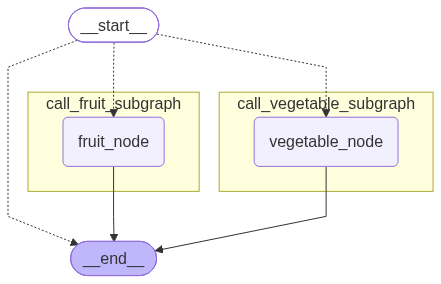

In [18]:
from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)

#### 12.2.2.6 场景六：Stateless 模式
子图完全无状态，不保存检查点，中断和多轮对话均不适用。适用于纯计算、无需追踪历史的场景。

In [19]:
from typing import TypedDict, Annotated
from operator import add
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

# 构建子图
class SubgraphState(TypedDict):
    raw_text: str
    clean_texts: Annotated[list[str], add]

def strip_node(state: SubgraphState) -> SubgraphState:
    raw_text = state["raw_text"]
    clean_text = raw_text.strip()

    return {
        "clean_texts": [clean_text]
    }

builder = StateGraph(state_schema=SubgraphState)
builder.add_node("strip_node", strip_node)
builder.add_edge(START, "strip_node")
builder.add_edge("strip_node", END)

# ==================================================
# 【策略切换点】只需修改这一行
subgraph = builder.compile(checkpointer=False)  # Stateless：无检查点
# subgraph = builder.compile(checkpointer=True)   # Per-thread：有状态（对比用）
# ==================================================

# 构建父图
class ParentState(TypedDict):
    input_texts: list[str]
    output_texts: Annotated[list[str], add]

def call_subgraph(state: ParentState) -> ParentState:
    input_texts = state["input_texts"]

    output_texts = []
    for input_text in input_texts:
        res = subgraph.invoke({"raw_text": input_text})
        output_texts += res["clean_texts"]

    return {
        "output_texts": output_texts
    }

builder = StateGraph(state_schema=ParentState)
builder.add_node("call_subgraph", call_subgraph)
builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "stateless-demo"}}

first_response = parent_graph.invoke(
    {
        "input_texts": ["  LangGraph 真有意思 ", "  我喜欢 LangChain "]
    },
    config = config
)
print("=" * 30, "-> 第一次运行结果 <-", "=" * 30)
rprint(first_response)

============================== -> 第一次运行结果 <- ==============================


{
    'input_texts': ['  LangGraph 真有意思 ', '  我喜欢 LangChain '],
    'output_texts': ['LangGraph 真有意思', '我喜欢 LangChain']
}

============================== -> 第二次运行结果 <- ==============================

{
    'input_texts': ['  Hello, LangGraph  ', '  Hello, LangChain '],
    'output_texts': [
        'LangGraph 真有意思',
        '我喜欢 LangChain',
        'Hello, LangGraph',
        'Hello, LangChain',
        'Hello, LangGraph',
        'Hello, LangChain'
    ]
}

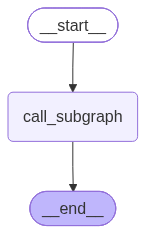

In [21]:
second_response = parent_graph.invoke(
    {
        "input_texts": ["  Hello, LangGraph  ", "  Hello, LangChain "]
    },
    config = config
)
rprint("=" * 30, "-> 第二次运行结果 <-", "=" * 30)
rprint(second_response)
from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)

# 总结

### 1. get_state() 和 get_state_history()

这两个方法都用于读取已保存的状态，不会执行图：`get_state()` 读取一个快照，`get_state_history()` 遍历历史快照。

以下签名对应当前本地的 `parent_graph`。`RemoteGraph`（远程图）还支持 `headers` 和 `params`，分别用于传递 HTTP 请求头和 URL 查询参数；本地版本不接受这两个参数。

#### get_state()

```python
get_state(
    self,
    config: RunnableConfig,
    *,
    subgraphs: bool = False,
) -> StateSnapshot
```

| 参数 | 含义 |
|---|---|
| `config` | 指定查询对象：`thread_id` 标识线程；`checkpoint_ns` 区分父图和子图；`checkpoint_id` 指定某个检查点，省略时读取最新快照。 |
| `subgraphs` | 是否展开子图状态。`True` 时，相关 `tasks[i].state` 会展开为子图的 `StateSnapshot`；默认通常只提供子图配置引用。 |

**返回值：** 一个 `StateSnapshot`，包含 `values`、`next`、`tasks`、`config` 等字段。

```python
snapshot = parent_graph.get_state(config, subgraphs=True)
print(snapshot.values)
```

#### get_state_history()

```python
get_state_history(
    self,
    config: RunnableConfig,
    *,
    filter: dict[str, Any] | None = None,
    before: RunnableConfig | None = None,
    limit: int | None = None,
) -> Iterator[StateSnapshot]
```

| 参数 | 含义 |
|---|---|
| `config` | 指定要查询的线程和检查点命名空间；传入子图配置即可查询子图历史。 |
| `filter` | 按检查点的 `metadata` 筛选，例如 `{"source": "loop"}`；不是筛选 `values`。 |
| `before` | 指定一个检查点配置，只查询比它更早的记录，不包含它本身。 |
| `limit` | 最多返回多少条记录；本地实现中，`None` 表示不限制数量。 |

**返回值：** `StateSnapshot` 的迭代器，按最新到最旧排列。用 `list()` 将其收集为列表：

```python
histories = list(parent_graph.get_state_history(config, limit=3))
```

签名中的 `self` 是自动传入的实例；`*` 表示后面的参数必须写参数名，例如 `limit=3`。

### 2. invoke() 的返回值为什么不同？

`invoke()` 是统一的调用入口，返回类型取决于调用对象及其输出定义。以下按本项目的常规调用方式归纳：

| 调用对象 | 常见返回值 | 取值方式 |
|---|---|---|
| 聊天模型 `model` | 一条 `AIMessage` | `result.content` |
| 绑定工具的聊天模型 `model.bind_tools(...)` | `AIMessage`，可能含工具调用请求 | `result.content`、`result.tool_calls` |
| 使用 `MessagesState` 的子图 | 含 `messages` 列表的状态字典 | `result["messages"][-1].content`（本例最终回复） |
| 本例自定义状态的父图 | 含 `user_input`、`assistant_response` 的状态字典 | `result["assistant_response"]` |
| `create_agent()` 创建的智能体 | 通常含 `messages` 的状态字典 | `result["messages"][-1].content`（正常完成后的最终回复） |
| `model \| StrOutputParser()` 组成的链 | 字符串 `str` | 直接使用 `result` |

**本例的数据层次：**

```python
response = model.invoke(messages)  # AIMessage：模型回复

# 节点返回状态更新，图将其合并到状态中
# return {"messages": [response]}

result = subgraph.invoke({"messages": messages})  # dict：子图输出状态
result["messages"]             # list：消息列表
result["messages"][-1]         # AIMessage：本例最后一条回复
result["messages"][-1].content # 回复正文
```

`messages`（复数）来自状态定义，并非所有 `invoke()` 都自带这个字段。父图把子图的最后一条回复提取成 `assistant_response`，因此父图输出使用该字段。

判断返回类型时，先看调用对象，再看图的输出定义；对于 `a | b | c` 这样的顺序链，看最后一个组件的输出。结构化输出包装（如 `with_structured_output()`）也会改变返回类型。不确定时可用 `type(result)` 检查。

`AIMessage.content` 可以是文本或内容块列表。模型已返回 `AIMessage` 时，通常直接使用该对象；重新创建 `AIMessage(content=response.content)` 会丢掉原对象中的工具调用、用量等信息。


### 3. 子图 Per-invocation、Per-thread、False 总结

前提：父图已通过 `compile(checkpointer=InMemorySaver())` 启用检查点。

六个场景其实在回答同一个问题：**子图这次运行时，能不能找回之前保存的状态？** 搞清楚子图状态存在哪里，所有现象都能推出来。

#### 3.1 一个模型：子图状态存在哪里

子图状态由三个要素定位：

| 定位要素 | 含义 | 由谁决定 |
|---|---|---|
| 存储器 | 保存检查点的对象，如 `InMemorySaver` | 父图编译时传入，子图只能借用 |
| `thread_id` | 线程（一段会话）的 ID | 调用父图时的 `config` |
| `checkpoint_ns` | 检查点命名空间，区分父图（`''`）和各个子图 | 按下表规则生成 |

子图命名空间最多由三部分组成：

| 组成部分 | 示例 | 来源 | 何时变化 |
|---|---|---|---|
| 节点名 | `call_subgraph` | 父图中调用子图的节点 | 不变 |
| `:任务ID` | `:35fb…` | 父图执行该节点时，由当时的父图检查点算出 | 每次父图 `invoke()` 都变；中断恢复时不变 |
| `\|序号` | `\|1` | 同一节点内第几次调用子图，第 0 次不加 | 只看调用位置，不看调用的是哪个子图 |

三种模式只在两处不同：用不用存储器，保不保留任务 ID。

```mermaid
flowchart TD
    A["子图.invoke()"] --> B{"子图的 checkpointer"}
    B -- "False" --> C["不用存储器<br/>每次从空状态开始，结束即丢弃"]
    B -- "None（默认）" --> D["借用父图存储器<br/>命名空间：<br/>节点名:任务ID|序号"]
    B -- "True" --> E["借用父图存储器<br/>命名空间：<br/>节点名|序号"]
    D --> F["任务ID 每次 invoke 都变<br/>只在同一次调用内连续（可中断恢复）"]
    E --> G["命名空间跨 invoke 固定<br/>同一线程内跨调用连续（有记忆）"]
```

#### 3.2 由模型推出三种模式的能力

| | `False`（Stateless） | `None`（Per-invocation，默认） | `True`（Per-thread） |
|---|---|---|---|
| 存储器 | 不使用 | 借用父图的 | 借用父图的 |
| 子图命名空间 | 无 | `节点名:任务ID\|序号` | `节点名\|序号` |
| 同一次调用内找回状态（中断恢复） | ❌ | ✅ | ✅ |
| 下一次父图 `invoke()` 找回状态（多轮记忆） | ❌ | ❌ | ✅ |
| 查看子图检查点 | ❌ | ✅ 每次调用各一份 | ✅ |

#### 3.3 六个场景串联

| 场景 | 起决定作用的规则 | `False` | `None` | `True` | 结论 |
|---|---|---|---|---|---|
| 一、中断 | 恢复时任务 ID 不变 | ❌ 每次从头重跑，反复中断 | ✅ | ✅ | 需要中断就不能用 `False` |
| 二、多轮对话 | 新的 `invoke()` 任务 ID 改变 | ❌ | ❌ 每轮重置 | ✅ | 需要记忆用 `True` |
| 三、同节点多次调用同一子图 | 序号跨轮固定 | ✅ 互不影响 | ✅ 互不影响 | ⚠️ 第 n 次调用接上一轮第 n 次的历史 | 要求互相独立用 `None` |
| 四、同节点调用不同子图 | 序号只看调用位置 | ✅ 无记忆 | ✅ 无记忆 | ⚠️ 调换顺序或跳过一次就串到别的子图的历史 | 需要记忆时改用场景五 |
| 五、独立节点调用不同子图 | 节点名不同，命名空间不同 | ✅ 无记忆 | ✅ 无记忆 | ✅ 各自记忆，互不干扰 | `True` 的推荐用法 |
| 六、Stateless | 不用存储器 | ✅ 子图每次干净 | ✅ 子图每次干净，但保存检查点 | ⚠️ 子图 `clean_texts` 跨轮累积 | 纯计算可用 `False` |

#### 3.4 容易混淆的几点

1. **`None` 不等于不持久化**：它会保存子图检查点，只是每次父图调用换一个命名空间。
2. **`True` 不会自己创建存储器**：它只借用父图的；最外层的图使用 `True` 会报错 `checkpointer=True cannot be used for root graphs.`。
3. **“Stateless 不累积”只指子图这一层**：父图有检查点、`thread_id` 相同、字段带 `add` 规约函数时，父图状态在三种模式下都会累积（场景六）。
4. **`True` 模式下本轮输入会追加到历史后面**：每轮都传 `SystemMessage` 会逐轮堆积（场景二）。
5. **`True` 模式按“节点名 + 调用序号”归属历史**，不按子图变量名（场景三、四）。
6. 中断恢复不是一次新调用,不会生成新的任务ID。这个"任务 ID"是父图执行到 subgraph_node（或 call_subgraph）这个节点那一刻，由当时的父图检查点算出来的一个标识。

#### 3.5 如何选择

```mermaid
flowchart TD
    Q1{"子图需要跨轮记忆？<br/>（如多轮对话）"}
    Q1 -- "是" --> T["checkpointer=True<br/>每个子图放在独立的父图节点中，<br/>同一节点不重复调用（场景二、五）"]
    Q1 -- "否" --> Q2{"子图内部使用 interrupt()，<br/>或需要查看子图检查点？"}
    Q2 -- "是" --> N["checkpointer=None（默认）<br/>（场景一、三、四）"]
    Q2 -- "否" --> F["None 或 False 均可<br/>纯计算可用 False，不写检查点（场景六）"]
```

# 问题
### 1. 为什么子图 compile 函数参数不同，会造成中断恢复的结果不同？

前提：父图已通过 `compile(checkpointer=InMemorySaver())` 启用检查点。需要区分“恢复同一次未完成的调用”和“调用完成后发起新调用”。

| 子图 `checkpointer` | 保存子图检查点 | 中断恢复 | 完成后再次调用时加载子图历史 |
|---|---|---|---|
| `None` 或省略 | 是，使用父图的存储器 | 支持 | 不加载，每次调用独立 |
| `True` | 是，使用父图的存储器 | 支持 | 同一线程、对应子图位置会加载 |
| `False` | 否 | 不支持正常恢复 | 不加载 |

`None` 不等于关闭持久化；`True` 也不会自动创建存储器。两者都依赖父图提供的存储器，区别在于子图状态是否跨调用延续。

**本例中 `None` 和 `True` 的恢复结果相同：**

1. 首次调用：执行 `strip`，进入 `punctuate`，停在第一个 `interrupt()`。
2. `Command(resume="!")`：从 `punctuate` 节点开头重新执行，第一个中断返回 `"!"`，停在第二个中断。
3. `Command(resume="~")`：再次执行 `punctuate`，第一个中断复用已保存的 `"!"`，第二个返回 `"~"`，最终得到 `LangGraph 真有意思!~`。

恢复时重跑的是中断所在的节点，并按中断出现的顺序复用已记录的恢复值；已保存检查点的 `strip` 不再执行。因此，`punctuate` 日志重复不代表恢复失败。两次恢复仍属于同一次子图调用，尚不能体现 `None` 与 `True` 的跨调用记忆差异。

**`False` 为什么反复中断？** 子图没有保存内部状态、中断任务和恢复值。父图恢复时只能从头重跑子图，因此每次都执行 `strip → punctuate`，重新触发第一个中断，中断 ID 也不断变化。出现 `__interrupt__` 只说明中断传播到了父图，不代表子图能恢复；父图检查点不能替代子图内部检查点。

### 2. 为什么同一父图节点中交换子图调用顺序，会导致历史错乱？

前提：父图启用检查点，两个子图都使用 `checkpointer=True`，多轮调用使用相同 `thread_id`。在同一个父图节点内，子图历史按运行时的调用位置关联，而不是按 `fruit_subgraph`、`vegetable_subgraph` 变量名关联。

**第一轮：先水果，后蔬菜。**

```python
fruit_response = fruit_subgraph.invoke({"messages": fruit_messages})
vegetable_response = vegetable_subgraph.invoke({"messages": vegetable_messages})
```

输入水果“桑葚”、蔬菜“西兰苔”。当前版本中，本例第一次调用使用 `call_subgraph` 命名空间，第二次使用 `call_subgraph|1`，分别保存水果和蔬菜历史。

**第二轮：交换顺序，先蔬菜，后水果。**

```python
vegetable_response = vegetable_subgraph.invoke({"messages": vegetable_messages})
fruit_response = fruit_subgraph.invoke({"messages": fruit_messages})
```

保持相同线程和检查点存储器，输入水果“苹果”、蔬菜“胡萝卜”：

| 调用位置 | 本轮执行的子图 | 读取的旧历史 | 本轮加入的消息 |
|---|---|---|---|
| 第一次 | 蔬菜子图 | 桑葚及水果子图的回复 | 胡萝卜 |
| 第二次 | 水果子图 | 西兰苔及蔬菜子图的回复 | 苹果 |

执行的子图和本轮输入都正确，但加载的旧历史属于另一个子图。两者都使用 `MessagesState`，消息还能正常合并，因此可能不报错，却发生上下文混用。条件分支跳过第一次调用，也会让原来的第二次调用占用第一位置。

**更稳健的做法：** 将水果和蔬菜分别放进父图中独立命名的节点，各自在节点函数中完成输入输出映射：

```python
# call_fruit 内只调用水果子图，call_vegetable 内只调用蔬菜子图
builder.add_node("call_fruit", call_fruit)
builder.add_node("call_vegetable", call_vegetable)
```

各自拥有稳定的命名空间后，跳过其中一个节点不会让另一个占用它的历史位置。如果不需要跨调用记忆，可以使用 `checkpointer=None`，让每次子图调用独立。

专有输入字段保证的是本轮输入路由正确；跨轮历史的正确归属还需要稳定的检查点命名空间。

### 3. 多轮对话中，为什么相同 `thread_id` 下子图的历史表现不同？

前提：父图启用检查点，子图使用 `MessagesState`，父图节点 `call_subgraph` 每轮调用一次子图，两轮使用相同 `thread_id`。

**子图状态的存放位置由两个值决定：** `thread_id` 指定线程；`checkpoint_ns`（检查点命名空间）区分父图和各个子图，父图为空字符串 `''`。子图运行时先按这两个值查找已有状态：找到就先恢复，再合并本次输入；找不到就从空状态开始。

`None` 和 `True` 的区别只在于子图命名空间是否包含任务 ID。任务 ID 是父图执行某个节点时生成的标识，由当时的父图检查点算出；父图每次 `invoke()` 都会产生新检查点，所以任务 ID 每轮都不同。

用假模型（只回复“我看到了 N 条消息”）验证，两轮调用的结果如下：

| 子图 `checkpointer` | 子图命名空间 | 第 1 轮 | 第 2 轮 | 第 2 轮后线程中的命名空间 |
|---|---|---|---|---|
| `None` 或省略 | `call_subgraph:<任务ID>` | 1 条 | 1 条 | `''`、`call_subgraph:35fb…`、`call_subgraph:0836…` |
| `True` | `call_subgraph` | 1 条 | 3 条 | `''`、`call_subgraph` |

- **`None`**：第 2 轮任务 ID 改变，子图查找的是一个新的、空的命名空间。第 1 轮历史仍在存储器中，只是不会被读取，所以子图只看到本轮消息。
- **`True`**：去掉 `:<任务ID>` 后命名空间固定。第 2 轮先恢复 `[Human1, AI1]`，再由 `add_messages` 追加本轮的 `Human2`，共 3 条。

**为什么 `True` 模式第二轮出现两条 `SystemMessage`？** `call_subgraph` 每轮都传入 `[SystemMessage, HumanMessage]`，两条消息都会追加到恢复出的历史后面。实际多轮对话中，系统提示应只在首轮传入，或在子图节点调用模型前临时拼接，否则会逐轮累积。

**和问题 1 的关系：** `None` 能中断恢复，是因为 `Command(resume=...)` 继续的是同一次未完成的调用，父图检查点没有前进，重跑任务的任务 ID 不变，因此能找回原命名空间。新的 `invoke()` 会推进父图检查点，任务 ID 随之改变。

**源码位置：** 当前环境（langgraph 1.2.16）`langgraph/pregel/main.py` 中的 `Pregel._own_checkpoint_config`。它只在 `checkpointer is True` 时生效，去掉命名空间每一段的 `:<任务ID>`，但保留 `|1` 这类调用序号；问题 2 中“按调用位置关联历史”就来自这一点。

### 4. Stateless 子图是什么？为什么第二次调用时 `output_texts` 仍会累积？

前提：父图启用检查点，两轮使用相同 `thread_id`；父图状态定义 `output_texts: Annotated[list[str], add]`；节点 `call_subgraph` 每轮循环调用两次子图。

**Stateless 指 `compile(checkpointer=False)`：** 子图不使用任何存储器，也不借用父图的存储器。每次 `invoke()` 都从空状态开始，运行结束后状态即丢弃，相当于调用一个普通函数。因此：不保存子图检查点（线程中只有父图命名空间 `''`）；中断无法恢复（见问题 1）；子图不跨调用记忆。

**累积发生在父图，而不是子图：**

1. 父图有检查点且 `thread_id` 相同，第 2 轮开始时先恢复上一轮的父图状态。
2. `output_texts` 的规约函数是 `add`（列表拼接），节点返回的新列表会拼接到旧列表后面，而不是覆盖旧值。

| 第 2 轮 | 值 |
|---|---|
| 父图恢复的 `output_texts` | `['LangGraph 真有意思', '我喜欢 LangChain']` |
| 两次子图调用返回的 `clean_texts` | `['Hello, LangGraph']`、`['Hello, LangChain']`（只有本轮结果） |
| 最终 `output_texts` | 旧的 2 条 + 本轮 2 条 |

对照验证：第 2 轮改用新的 `thread_id`，结果只有本轮 2 条；同一输出中的 `input_texts` 没有规约函数，只保留第 2 轮的值。

**对比 `True`：父图和子图都累积，共 6 条。** 子图在同一节点内被调用两次，历史分别存于 `call_subgraph` 和 `call_subgraph|1`（见问题 2）。第 2 轮的两次调用各自先恢复上一轮的 1 条，再追加本轮 1 条，分别返回 `['LangGraph 真有意思', 'Hello, LangGraph']` 和 `['我喜欢 LangChain', 'Hello, LangChain']`；节点把它们拼成 4 条，再由父图的 `add` 接到旧的 2 条后面，因此出现重复。“Stateless 不累积历史”指的是子图这一层；父图这一层，三种模式都会累积。

**不需要父图累积时：** 去掉 `output_texts` 的 `add`，改为普通 `list[str]`，让每轮结果覆盖旧值；或者为每个独立任务使用不同的 `thread_id`。

**源码位置：** 当前环境（langgraph 1.2.16）`langgraph/pregel/main.py` 中的 `Pregel._resolve_checkpointer`。`checkpointer is False` 时它直接返回 `None`，这个判断位于“使用父图传入的存储器”之前，所以 Stateless 子图拿不到父图的存储器。